In [44]:
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader

import torchvision
from torchvision.transforms import v2

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cpu


## Data

In [45]:
mnist_train = torchvision.datasets.MNIST(
  root="./data", 
  train=True, 
  download=True,
  transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

mnist_test = torchvision.datasets.MNIST(
  root="./data",
  train=False,
  download=True,
  transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
) 

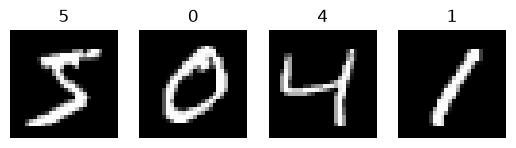

In [46]:
fig, axes = plt.subplots(1, 4)

for idx, ax in enumerate(axes):
  ax.axis('off')
  ax.set_title(mnist_train.targets[idx].item())
  ax.imshow(mnist_train.data[idx], cmap='gray')

plt.show()

In [47]:
train_dataloader = DataLoader(mnist_train, batch_size=128, shuffle=True)
test_dataloader = DataLoader(mnist_test, batch_size=128, shuffle=True)

Model Set-up

In [48]:
# Weighting initialisation for generator
# >> sensitive to initial params

def weight_init(m):
  name = m.__class__.__name__

  if name.find('Conv') != -1:
    # Convolution layer
    nn.init.normal_(m.weight.data, 0.0, 0.02)  
  elif name.find('Batch') != -1:
    # Batch normalisation layer
    nn.init.normal_(m.weight.data, 0.0, 0.02)
    nn.init.constant_(m.bias.data, 0.0)

## Generator

In [49]:
class Generator(nn.Module):
  def __init__(self):
    super(Generator, self).__init__()
    self.generate = nn.Sequential(
      # Linear combinations of latent spcae
      nn.Linear(LATENT_SPACE_SIZE, 128*7*7),
      nn.Unflatten(1, torch.Size([128, 7, 7])),
      torch.nn.BatchNorm2d(128),
      nn.ReLU(True),
       
      # Transpose 128*7*7 >> 64*14*14
      nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
      torch.nn.BatchNorm2d(64),
      nn.ReLU(True),

      # Transpose 64*14*14 >> 1*28*28 (MNIST image size)
      nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1),
      nn.Tanh(),
    )

  def forward(self, x):
    return self.generate(x)


In [50]:
generator = Generator().to(device)
generator.apply(weight_init)
print(generator)

Generator(
  (generate): Sequential(
    (0): Linear(in_features=50, out_features=6272, bias=True)
    (1): Unflatten(dim=1, unflattened_size=torch.Size([128, 7, 7]))
    (2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU(inplace=True)
    (4): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Tanh()
  )
)


## Discriminator

In [51]:
class Discriminator(nn.Module):
  def __init__(self):
    super(Discriminator, self).__init__()
    self.disc = nn.Sequential(
      # 1*28*28 >> 64*14*14
      nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1, bias=False),
      nn.BatchNorm2d(64),
      nn.LeakyReLU(inplace=True),
      
      # 64*14*14 >> 128*7*7
      nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
      nn.BatchNorm2d(128),
      nn.LeakyReLU(inplace=True),

      # 128*7*7 >> a scalar
      nn.Conv2d(128, 1, kernel_size=7, stride=1, padding=0),
      nn.Sigmoid()
    )

  def forward(self, x):
    return self.disc(x)

In [52]:
discriminator = Discriminator().to(device)
discriminator.apply(weight_init)
print(discriminator)

Discriminator(
  (disc): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.01, inplace=True)
    (3): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.01, inplace=True)
    (6): Conv2d(128, 1, kernel_size=(7, 7), stride=(1, 1))
    (7): Sigmoid()
  )
)


## Loss